# Sentiment Analysis — 2024 US Presidential Election
## Reddit r/politics · June–November 2024

> *Can Reddit comment sentiment serve as a signal for public political opinion,
> and does it track with national polls during the 2024 US Presidential Election?*

Uses the **12,000-comment candidate basis** (all 4 model labels, saved by `Models.ipynb`)
to track sentiment toward Trump and Harris across the campaign and compare against polling.

| Section | Content |
|---|---|
| 0 | Imports & Setup |
| 1 | Load Results |
| 2 | Load Polling Data |
| 3 | Sentiment Over Time — Model by Model |
| 4 | Aggregated Consensus Sentiment vs Polling |
| 5 | Net Sentiment (% positive − % negative) |
| 6 | Trump vs Harris Sentiment Gap |
| 7 | Key Event Impact Analysis |
| 8 | Correlation with Polling |

## 0. Imports & Setup

In [11]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
from scipy import stats

BASE_DIR    = Path('..').resolve()
DATA_DIR    = BASE_DIR / 'Datasources'
RESULTS_DIR = DATA_DIR / 'model_results'

plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.family'] = 'sans-serif'
sns.set_style('whitegrid')

LABEL_ORDER  = ['positive', 'neutral', 'negative']
MONTHS_ORDER = ['June', 'July', 'August', 'September', 'October', 'November']
MONTH_MID    = {
    'June': '2024-06-15', 'July': '2024-07-15', 'August': '2024-08-15',
    'September': '2024-09-15', 'October': '2024-10-15', 'November': '2024-11-03',
}
EVENTS = {
    '2024-06-27': 'Biden-Trump debate',
    '2024-07-13': 'Trump assassination attempt',
    '2024-07-21': 'Biden drops out',
    '2024-08-06': 'Walz VP pick',
    '2024-09-10': 'Harris-Trump debate',
    '2024-10-01': 'Walz-Vance VP debate',
    '2024-10-05': '2nd assassination attempt',
    '2024-11-05': 'Election Day',
}
MODELS       = ['vader_label', 'bow_label', 'rob_label', 'gpt_label']
MODEL_NAMES  = ['VADER', 'BoW', 'RoBERTa', 'GPT-4o-mini']
MODEL_COLORS = ['#aec7e8', '#2ca02c', '#9467bd', '#ff7f0e']
print('Setup done.')

Setup done.


## 1. Load Results

Load `candidate_basis_all_labels.parquet` — saved by `Models.ipynb` Section 7.
Contains 12,000 candidate-related comments with all 4 model labels.

In [12]:
_BASIS = RESULTS_DIR / 'candidate_basis_all_labels.parquet'
assert _BASIS.exists(), f'Run Models.ipynb sections 0-7 first: {_BASIS}'

df = pd.read_parquet(_BASIS)
df['date_day'] = pd.to_datetime(df['date_day'])

df_trump  = df[df['mentions_trump']].copy()
df_harris = df[df['mentions_harris_biden']].copy()
x_dates   = pd.to_datetime([MONTH_MID[m] for m in MONTHS_ORDER])

print(f'Total comments : {len(df):,}')
print(f'Trump comments : {len(df_trump):,}')
print(f'Harris comments: {len(df_harris):,}')
print(f'Both mentioned : {(df["mentions_trump"] & df["mentions_harris_biden"]).sum():,}')
print()
print('Label distributions:')
for col, name in zip(MODELS, MODEL_NAMES):
    if col not in df.columns: continue
    vc   = df[col].value_counts()
    dist = '  '.join([f'{l}: {vc.get(l,0)/len(df)*100:.1f}%' for l in LABEL_ORDER])
    print(f'  {name:14s}: {dist}')

Total comments : 12,000
Trump comments : 8,522
Harris comments: 5,743
Both mentioned : 2,265

Label distributions:
  VADER         : positive: 45.3%  neutral: 13.7%  negative: 41.0%
  BoW           : positive: 43.1%  neutral: 17.3%  negative: 39.6%
  RoBERTa       : positive: 7.4%  neutral: 29.4%  negative: 63.2%
  GPT-4o-mini   : positive: 19.1%  neutral: 10.8%  negative: 70.2%


## 2. Load Polling Data

55 nationwide polls (Jul–Nov 2024) from major pollsters, aggregated from Wikipedia.

In [13]:
df_polls = pd.read_excel(DATA_DIR / '2024_Election_Polls.xlsx', header=1, skiprows=[2])
df_polls.columns = ['pollster','dates','end_date','grade','sample_size',
                    'harris_pct','trump_pct','margin','month','event']
df_polls = df_polls[pd.to_numeric(df_polls['harris_pct'], errors='coerce').notna()].copy()
df_polls['end_date']   = pd.to_datetime(df_polls['end_date'])
df_polls['harris_pct'] = pd.to_numeric(df_polls['harris_pct'])
df_polls['trump_pct']  = pd.to_numeric(df_polls['trump_pct'])
df_polls['margin']     = pd.to_numeric(df_polls['margin'])
df_polls = df_polls[df_polls['end_date'].notna() & (df_polls['end_date'] < '2024-11-05')]
df_polls = df_polls.sort_values('end_date')

# 7-day rolling average
poll_weekly = (df_polls.set_index('end_date')[['harris_pct','trump_pct','margin']]
               .resample('7D').mean().dropna())

# Monthly average for correlation analysis
df_polls['month_name'] = df_polls['end_date'].dt.strftime('%B')
poll_monthly = df_polls.groupby('month_name')[['harris_pct','trump_pct','margin']].mean()

print(f'Polls: {len(df_polls)}  |  {df_polls["end_date"].min().date()} -> {df_polls["end_date"].max().date()}')
print(f'Weekly points: {len(poll_weekly)}')

Polls: 50  |  2024-07-23 -> 2024-11-04
Weekly points: 15


### Helpers

In [14]:
def monthly_pct(subset, col, label):
    return (subset.groupby('month')[col]
            .apply(lambda x: (x == label).mean() * 100)
            .reindex(MONTHS_ORDER))

def monthly_pos(subset, col): return monthly_pct(subset, col, 'positive')
def monthly_neg(subset, col): return monthly_pct(subset, col, 'negative')
def monthly_net(subset, col): return monthly_pos(subset, col) - monthly_neg(subset, col)

def add_events(ax, y=95, fontsize=6.5):
    for d_str, label in EVENTS.items():
        d = pd.to_datetime(d_str)
        ax.axvline(d, color='gray', lw=0.8, ls=':', alpha=0.6)
        ax.text(d, y, label, rotation=90, fontsize=fontsize,
                color='gray', va='top', ha='right')

print('Helpers defined.')

Helpers defined.


## 3. Sentiment Over Time — Model by Model

One panel per model. Each shows % positive for Trump-mentioned vs Harris-mentioned
comments per month, with polling on a secondary axis.

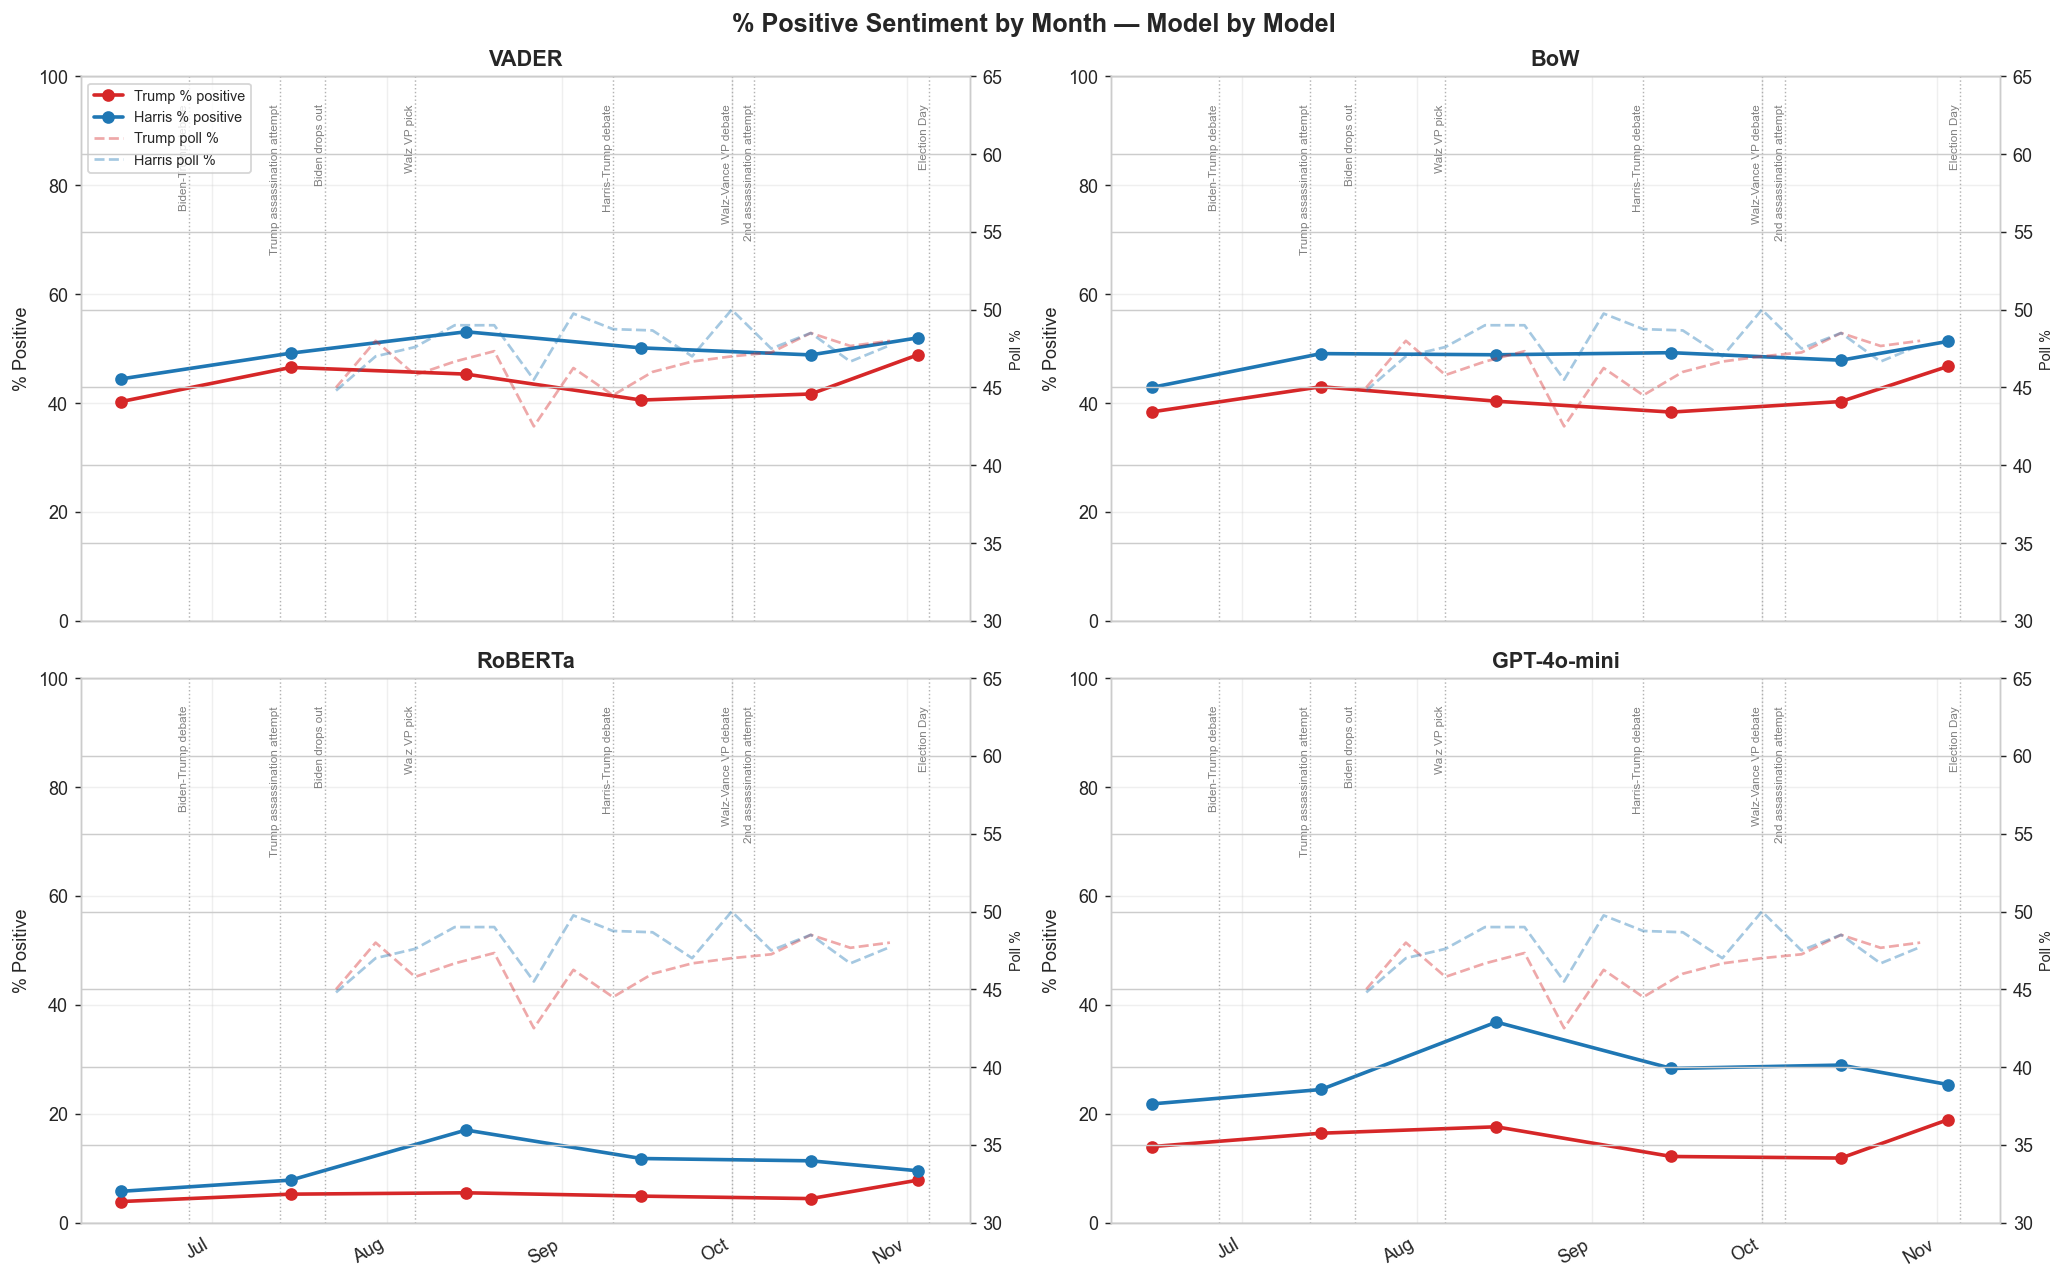

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
fig.suptitle('% Positive Sentiment by Month — Model by Model', fontsize=14, fontweight='bold')
axes = axes.flatten()

for idx, (col, name) in enumerate(zip(MODELS, MODEL_NAMES)):
    ax = axes[idx]
    if col in df_trump.columns:
        ax.plot(x_dates, monthly_pos(df_trump, col).values,
                marker='o', color='#d62728', lw=2, label='Trump % positive')
    if col in df_harris.columns:
        ax.plot(x_dates, monthly_pos(df_harris, col).values,
                marker='o', color='#1f77b4', lw=2, label='Harris % positive')
    ax2 = ax.twinx()
    ax2.plot(poll_weekly.index, poll_weekly['trump_pct'],
             color='#d62728', lw=1.5, ls='--', alpha=0.4, label='Trump poll %')
    ax2.plot(poll_weekly.index, poll_weekly['harris_pct'],
             color='#1f77b4', lw=1.5, ls='--', alpha=0.4, label='Harris poll %')
    ax2.set_ylim(30, 65); ax2.set_ylabel('Poll %', fontsize=8)
    add_events(ax)
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_ylim(0, 100); ax.set_ylabel('% Positive')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.grid(True, alpha=0.3)
    if idx == 0:
        l1, lb1 = ax.get_legend_handles_labels()
        l2, lb2 = ax2.get_legend_handles_labels()
        ax.legend(l1+l2, lb1+lb2, fontsize=8, loc='upper left')

plt.gcf().autofmt_xdate(); plt.tight_layout(); plt.show()

## 4. Aggregated Consensus Sentiment vs Polling

Average % positive across all 4 models into a single consensus line per candidate.
Shaded band shows the spread between models (disagreement range).

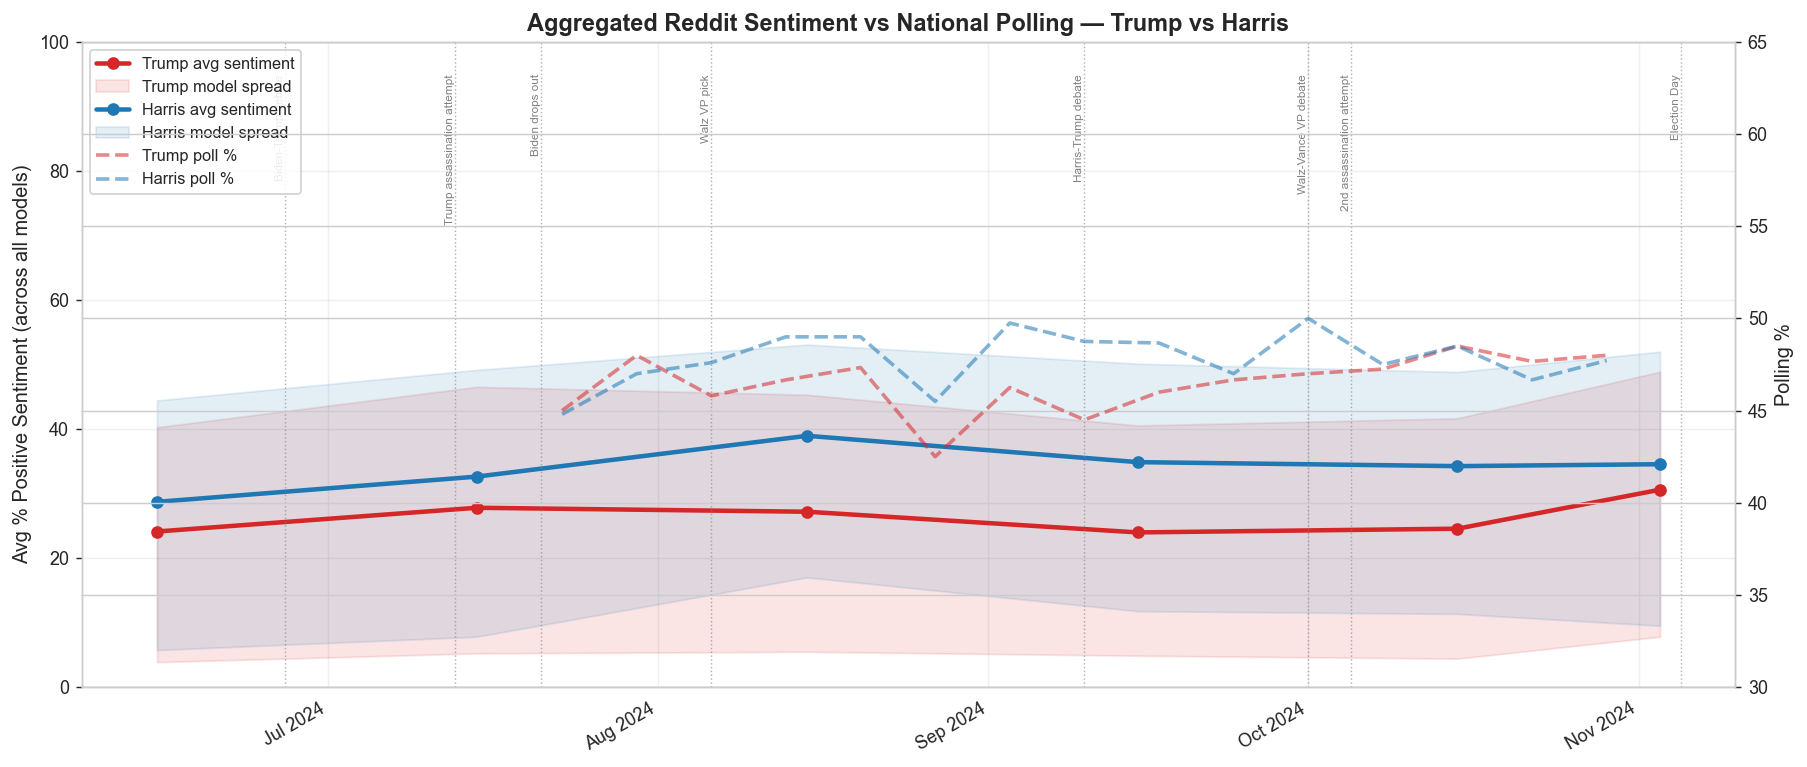

In [16]:
fig, ax = plt.subplots(figsize=(14, 6))

for df_cand, cand, color in [
    (df_trump,  'Trump',  '#d62728'),
    (df_harris, 'Harris', '#1f77b4'),
]:
    rates = np.array([monthly_pos(df_cand, c).values
                      for c in MODELS if c in df_cand.columns])
    agg = np.nanmean(rates, axis=0)
    ax.plot(x_dates, agg, marker='o', lw=2.5, color=color,
            label=f'{cand} avg sentiment')
    ax.fill_between(x_dates,
                    np.nanmin(rates, axis=0), np.nanmax(rates, axis=0),
                    alpha=0.12, color=color, label=f'{cand} model spread')

ax2 = ax.twinx()
ax2.plot(poll_weekly.index, poll_weekly['trump_pct'],
         color='#d62728', lw=2, ls='--', alpha=0.55, label='Trump poll %')
ax2.plot(poll_weekly.index, poll_weekly['harris_pct'],
         color='#1f77b4', lw=2, ls='--', alpha=0.55, label='Harris poll %')
ax2.set_ylabel('Polling %', fontsize=11); ax2.set_ylim(30, 65)

add_events(ax)
ax.set_ylim(0, 100)
ax.set_ylabel('Avg % Positive Sentiment (across all models)', fontsize=11)
ax.set_title('Aggregated Reddit Sentiment vs National Polling — Trump vs Harris',
             fontsize=13, fontweight='bold')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.grid(True, alpha=0.3)
l1, lb1 = ax.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, lb1+lb2, loc='upper left', fontsize=9, framealpha=0.85)
plt.gcf().autofmt_xdate(); plt.tight_layout(); plt.show()

## 5. Net Sentiment (% Positive − % Negative)

Net sentiment removes the neutral class and gives a cleaner directional signal.
Positive values = net positive Reddit opinion, negative = net negative.

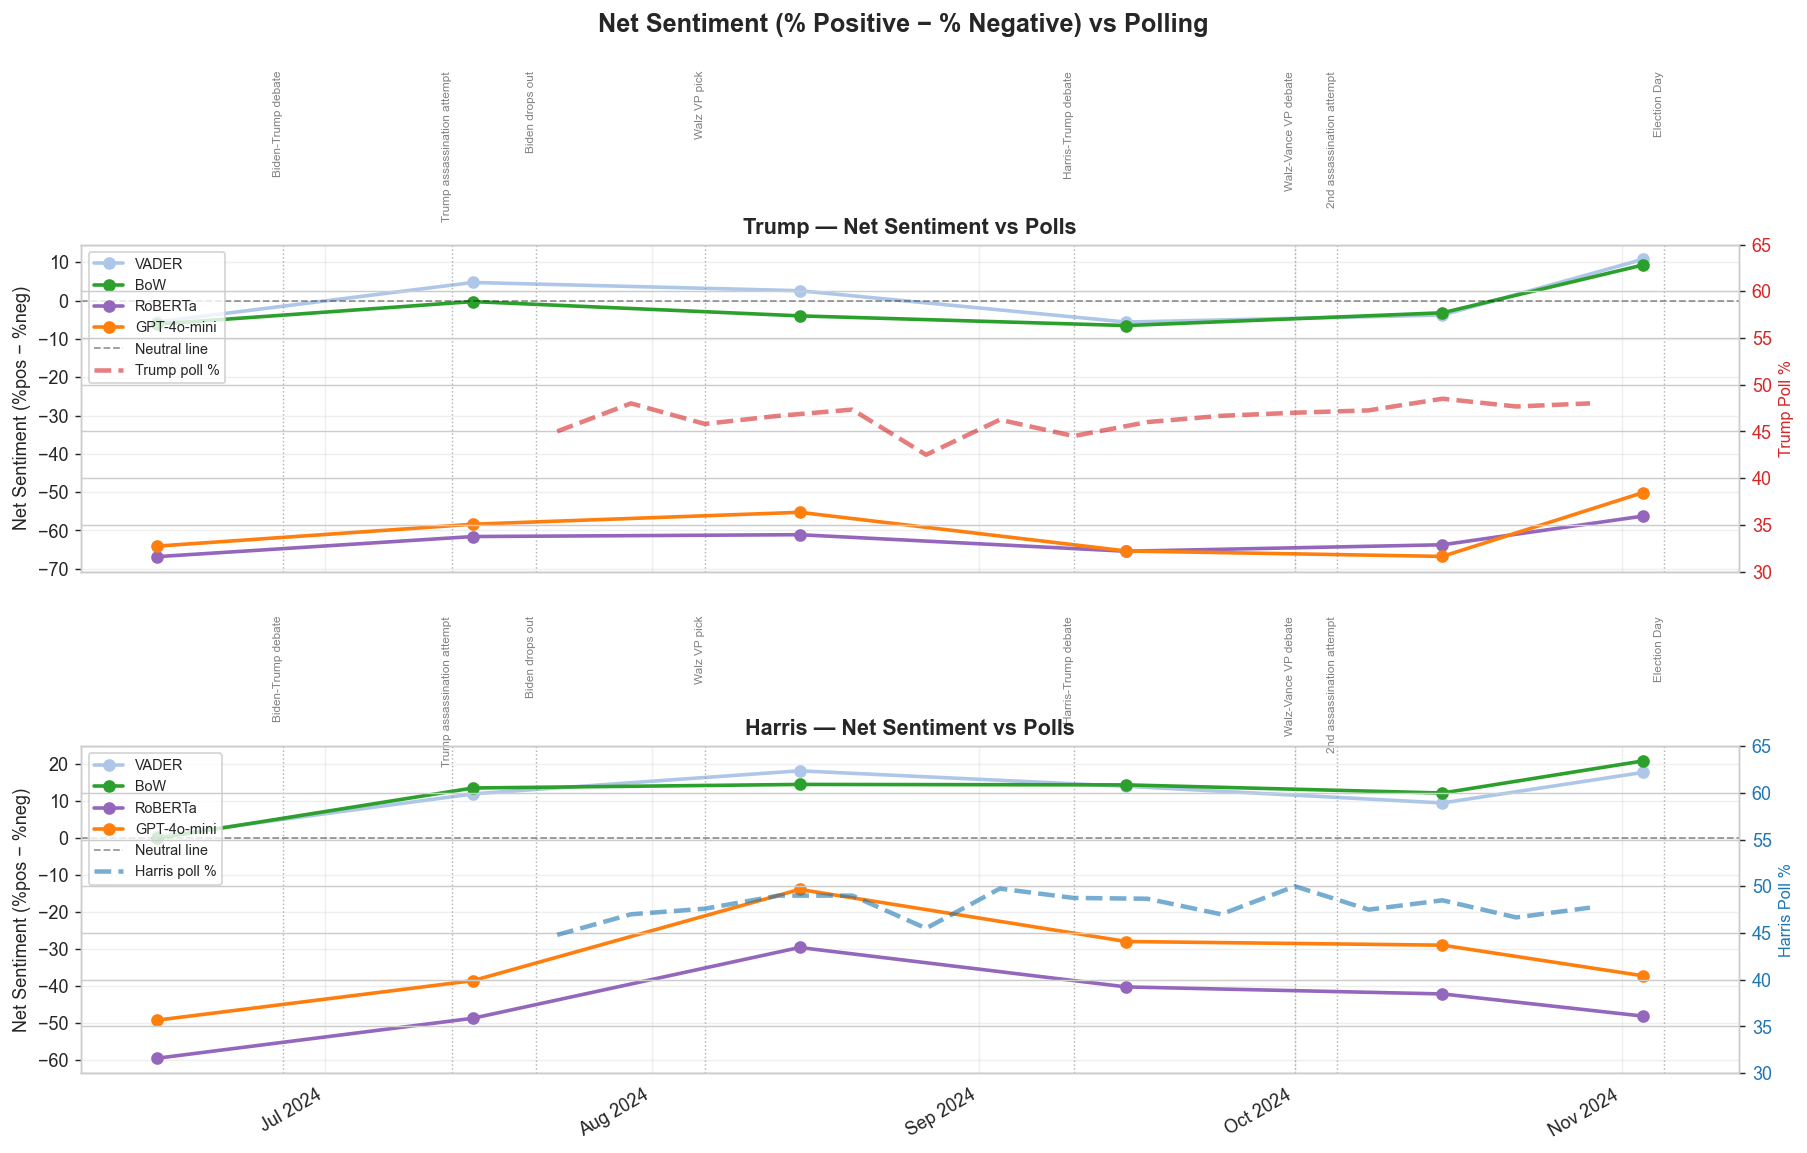

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
fig.suptitle('Net Sentiment (% Positive − % Negative) vs Polling', fontsize=14, fontweight='bold')

for ax, df_cand, cand, poll_col, color in [
    (axes[0], df_trump,  'Trump',  'trump_pct',  '#d62728'),
    (axes[1], df_harris, 'Harris', 'harris_pct', '#1f77b4'),
]:
    for col, name, mcolor in zip(MODELS, MODEL_NAMES, MODEL_COLORS):
        if col not in df_cand.columns: continue
        net = monthly_net(df_cand, col).values
        ax.plot(x_dates, net, marker='o', lw=2, color=mcolor, label=f'{name}')
    ax.axhline(0, color='black', lw=1, ls='--', alpha=0.4, label='Neutral line')
    ax2 = ax.twinx()
    ax2.plot(poll_weekly.index, poll_weekly[poll_col],
             color=color, lw=2.5, ls='--', alpha=0.6, label=f'{cand} poll %')
    ax2.set_ylim(30, 65)
    ax2.set_ylabel(f'{cand} Poll %', color=color, fontsize=9)
    ax2.tick_params(axis='y', labelcolor=color)
    add_events(ax, y=60)
    ax.set_ylabel('Net Sentiment (%pos − %neg)')
    ax.set_title(f'{cand} — Net Sentiment vs Polls', fontweight='bold')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.grid(True, alpha=0.3)
    l1, lb1 = ax.get_legend_handles_labels()
    l2, lb2 = ax2.get_legend_handles_labels()
    ax.legend(l1+l2, lb1+lb2, fontsize=8, loc='upper left')

plt.gcf().autofmt_xdate(); plt.tight_layout(); plt.show()

## 6. Trump vs Harris Sentiment Gap

Harris sentiment minus Trump sentiment per model.
Positive gap = Reddit more positive about Harris; negative = more positive about Trump.
Compare against polling margin (Harris % − Trump %).

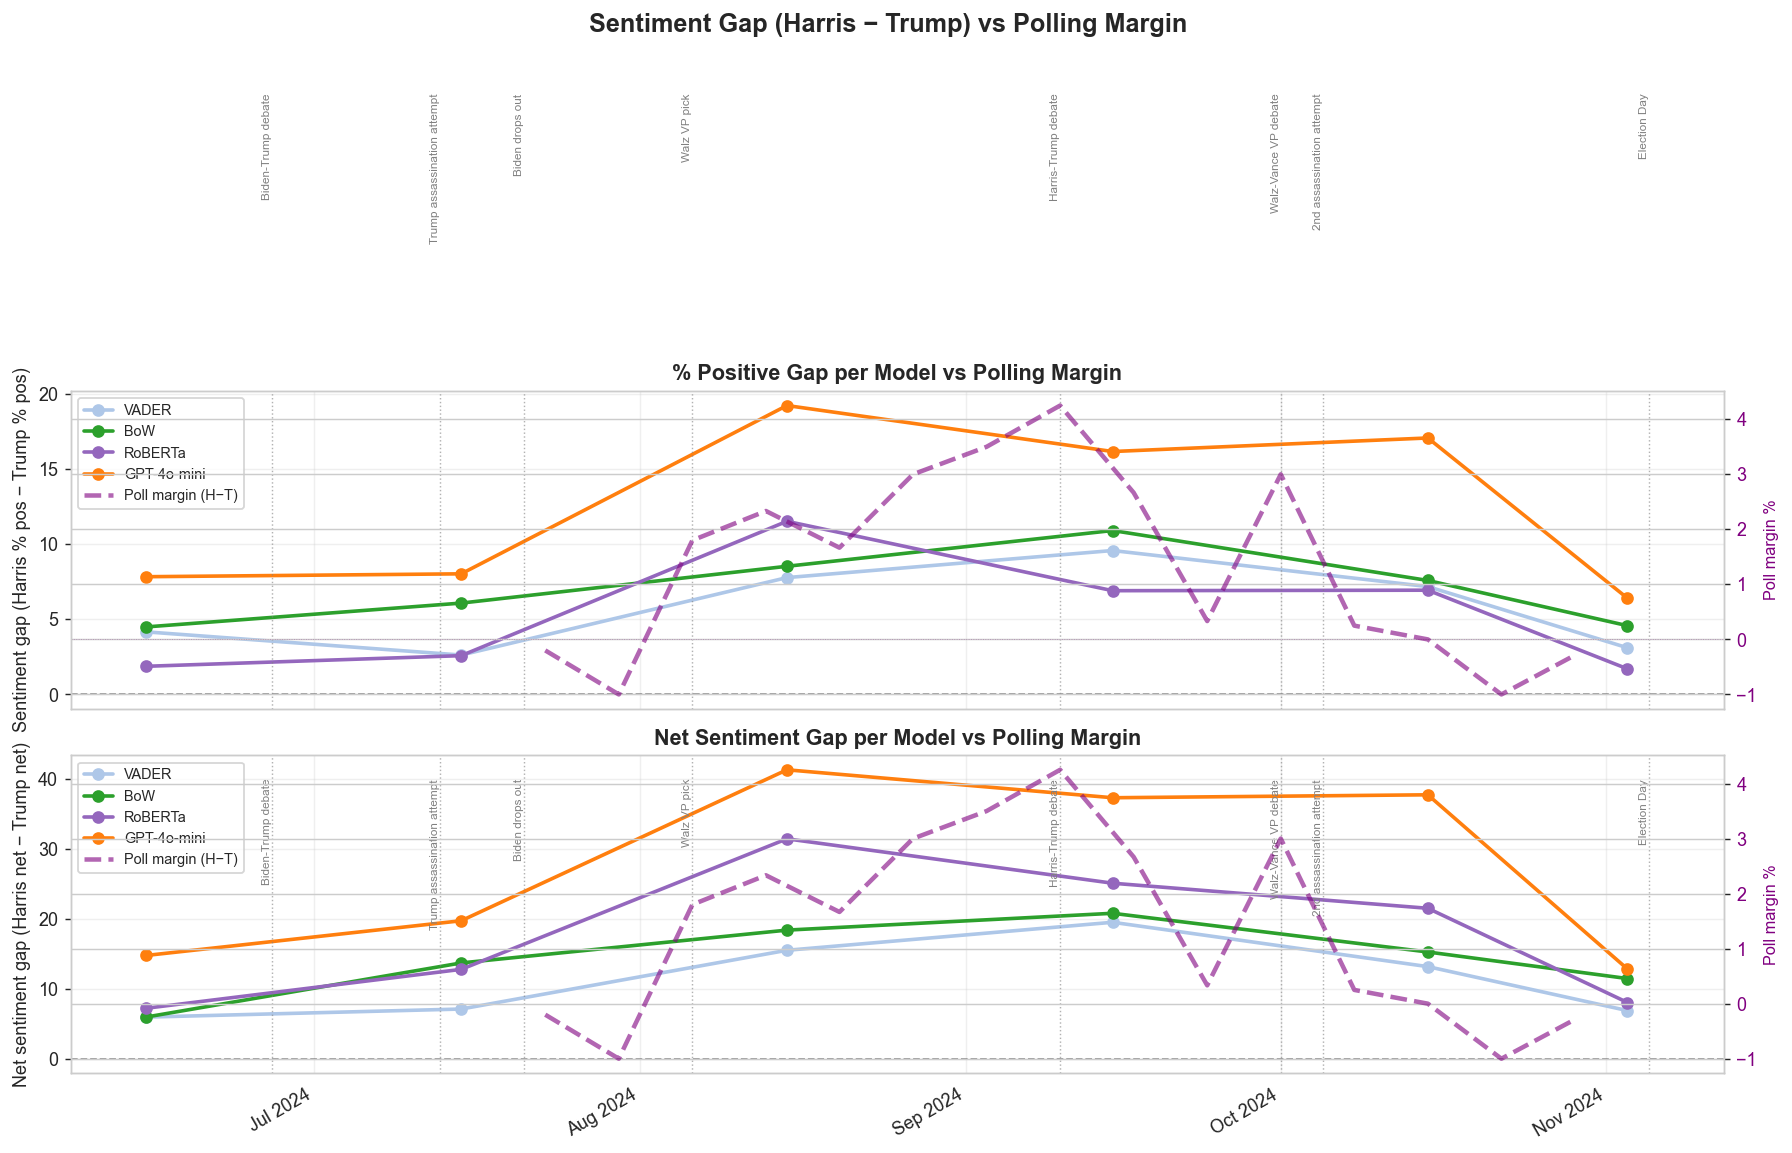

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
fig.suptitle('Sentiment Gap (Harris − Trump) vs Polling Margin', fontsize=14, fontweight='bold')

# Top: % positive gap
ax = axes[0]
for col, name, color in zip(MODELS, MODEL_NAMES, MODEL_COLORS):
    if col not in df.columns: continue
    gap = monthly_pos(df_harris, col).values - monthly_pos(df_trump, col).values
    ax.plot(x_dates, gap, marker='o', lw=2, color=color, label=name)
ax.axhline(0, color='black', lw=1, ls='--', alpha=0.4)
ax2 = ax.twinx()
ax2.plot(poll_weekly.index, poll_weekly['margin'],
         color='purple', lw=2.5, ls='--', alpha=0.6, label='Poll margin (H−T)')
ax2.axhline(0, color='purple', lw=0.5, ls=':', alpha=0.3)
ax2.set_ylabel('Poll margin %', color='purple', fontsize=9)
ax2.tick_params(axis='y', labelcolor='purple')
add_events(ax, y=40)
ax.set_ylabel('Sentiment gap (Harris % pos − Trump % pos)')
ax.set_title('% Positive Gap per Model vs Polling Margin', fontweight='bold')
ax.grid(True, alpha=0.3)
l1, lb1 = ax.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, lb1+lb2, fontsize=8, loc='upper left')

# Bottom: net sentiment gap
ax = axes[1]
for col, name, color in zip(MODELS, MODEL_NAMES, MODEL_COLORS):
    if col not in df.columns: continue
    net_gap = monthly_net(df_harris, col).values - monthly_net(df_trump, col).values
    ax.plot(x_dates, net_gap, marker='o', lw=2, color=color, label=name)
ax.axhline(0, color='black', lw=1, ls='--', alpha=0.4)
ax2 = ax.twinx()
ax2.plot(poll_weekly.index, poll_weekly['margin'],
         color='purple', lw=2.5, ls='--', alpha=0.6, label='Poll margin (H−T)')
ax2.set_ylabel('Poll margin %', color='purple', fontsize=9)
ax2.tick_params(axis='y', labelcolor='purple')
add_events(ax, y=40)
ax.set_ylabel('Net sentiment gap (Harris net − Trump net)')
ax.set_title('Net Sentiment Gap per Model vs Polling Margin', fontweight='bold')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.grid(True, alpha=0.3)
l1, lb1 = ax.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, lb1+lb2, fontsize=8, loc='upper left')

plt.gcf().autofmt_xdate(); plt.tight_layout(); plt.show()

## 7. Key Event Impact Analysis

Compare sentiment in the week before vs the week after each major campaign event.
Uses the full `df_comments_vader.parquet` for richer day-level data.

  Event                      Before (7d)   After (7d)   Change
  --------------------------------------------------------------
  Biden drops out                  39.5%         43.1%  ▲   3.6pp
  Walz VP pick                     40.8%         41.7%  ▲   0.9pp
  Harris-Trump debate              40.2%         37.3%  ▼   2.9pp
  Election Day                     40.9%         40.5%  ▼   0.4pp


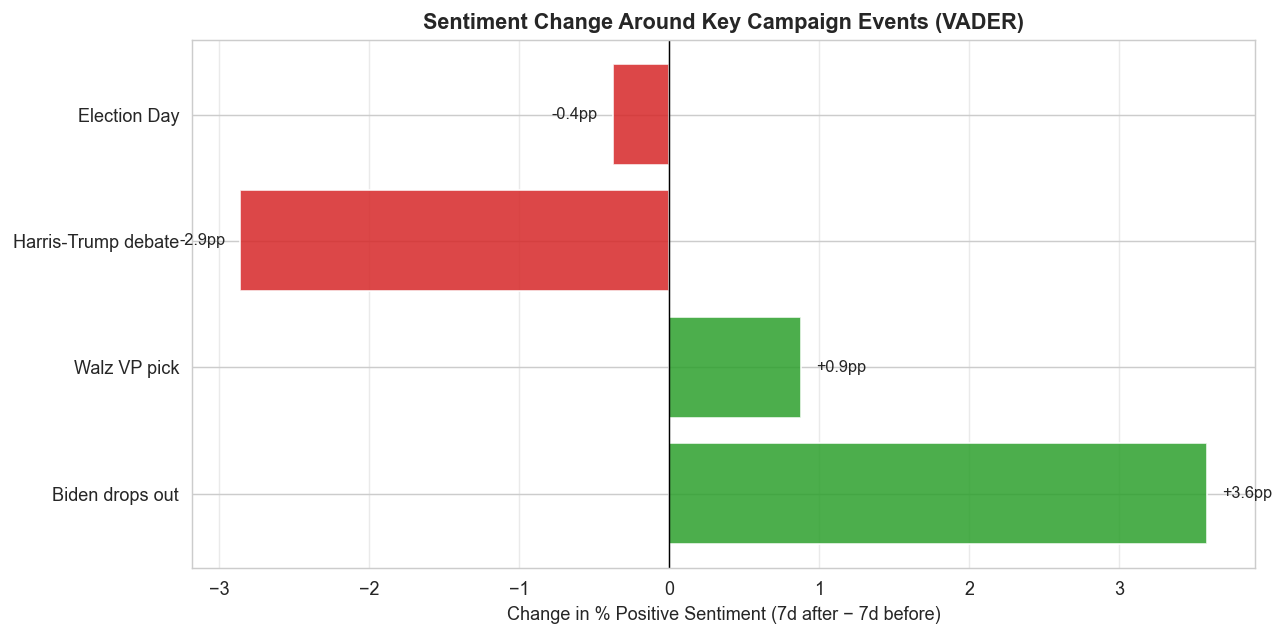

In [19]:
# Load full dataset for daily resolution
df_full = pd.read_parquet(DATA_DIR / 'df_comments_vader.parquet')
df_full['date_day'] = pd.to_datetime(df_full['date_day'])

EVENT_DATES = {
    'Biden drops out':      '2024-07-21',
    'Walz VP pick':         '2024-08-06',
    'Harris-Trump debate':  '2024-09-10',
    'Election Day':         '2024-11-05',
}

print(f'  {"Event":<25} {"Before (7d)":>12} {"After (7d)":>12} {"Change":>8}')
print('  ' + '-' * 62)

rows = []
for event_name, date_str in EVENT_DATES.items():
    d     = pd.Timestamp(date_str)
    before = df_full[(df_full['date_day'] >= d - pd.Timedelta(days=7)) &
                     (df_full['date_day'] <  d)]
    after  = df_full[(df_full['date_day'] >= d) &
                     (df_full['date_day'] <  d + pd.Timedelta(days=7))]
    if len(before) == 0 or len(after) == 0: continue
    pct_before = (before['vader_label'] == 'positive').mean() * 100
    pct_after  = (after['vader_label']  == 'positive').mean() * 100
    change     = pct_after - pct_before
    rows.append({'event': event_name, 'before': pct_before,
                 'after': pct_after, 'change': change})
    arrow = '▲' if change > 0 else '▼'
    print(f'  {event_name:<25} {pct_before:>11.1f}%  {pct_after:>11.1f}%  {arrow}{abs(change):>6.1f}pp')

# Bar chart of changes
df_events = pd.DataFrame(rows)
colors = ['#2ca02c' if c > 0 else '#d62728' for c in df_events['change']]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(df_events['event'], df_events['change'], color=colors, alpha=0.85)
ax.axvline(0, color='black', lw=0.8)
for bar, val in zip(bars, df_events['change']):
    ax.text(val + (0.1 if val >= 0 else -0.1), bar.get_y() + bar.get_height()/2,
            f'{val:+.1f}pp', va='center', ha='left' if val >= 0 else 'right', fontsize=9)
ax.set_xlabel('Change in % Positive Sentiment (7d after − 7d before)')
ax.set_title('Sentiment Change Around Key Campaign Events (VADER)', fontweight='bold')
ax.grid(axis='x', alpha=0.4)
plt.tight_layout(); plt.show()

## 8. Correlation with Polling

Pearson correlation between monthly Reddit sentiment and monthly polling averages.
Tests whether Reddit sentiment tracks real-world poll movement.

Correlation — Monthly Sentiment vs Monthly Polling

  Model          Candidate  Metric        Pearson r    p-value  Sig
  -----------------------------------------------------------------
  VADER          Trump      % positive       0.1601     0.7970     
  VADER          Trump      net sent.        0.2315     0.7079     
  VADER          Harris     % positive       0.3889     0.5176     
  VADER          Harris     net sent.        0.3261     0.5923     

  BoW            Trump      % positive       0.4328     0.4667     
  BoW            Trump      net sent.        0.5564     0.3300     
  BoW            Harris     % positive       0.0696     0.9114     
  BoW            Harris     net sent.        0.1934     0.7552     

  RoBERTa        Trump      % positive       0.4682     0.4265     
  RoBERTa        Trump      net sent.        0.4611     0.4344     
  RoBERTa        Harris     % positive       0.5771     0.3083     
  RoBERTa        Harris     net sent.        0.5133     0.3764

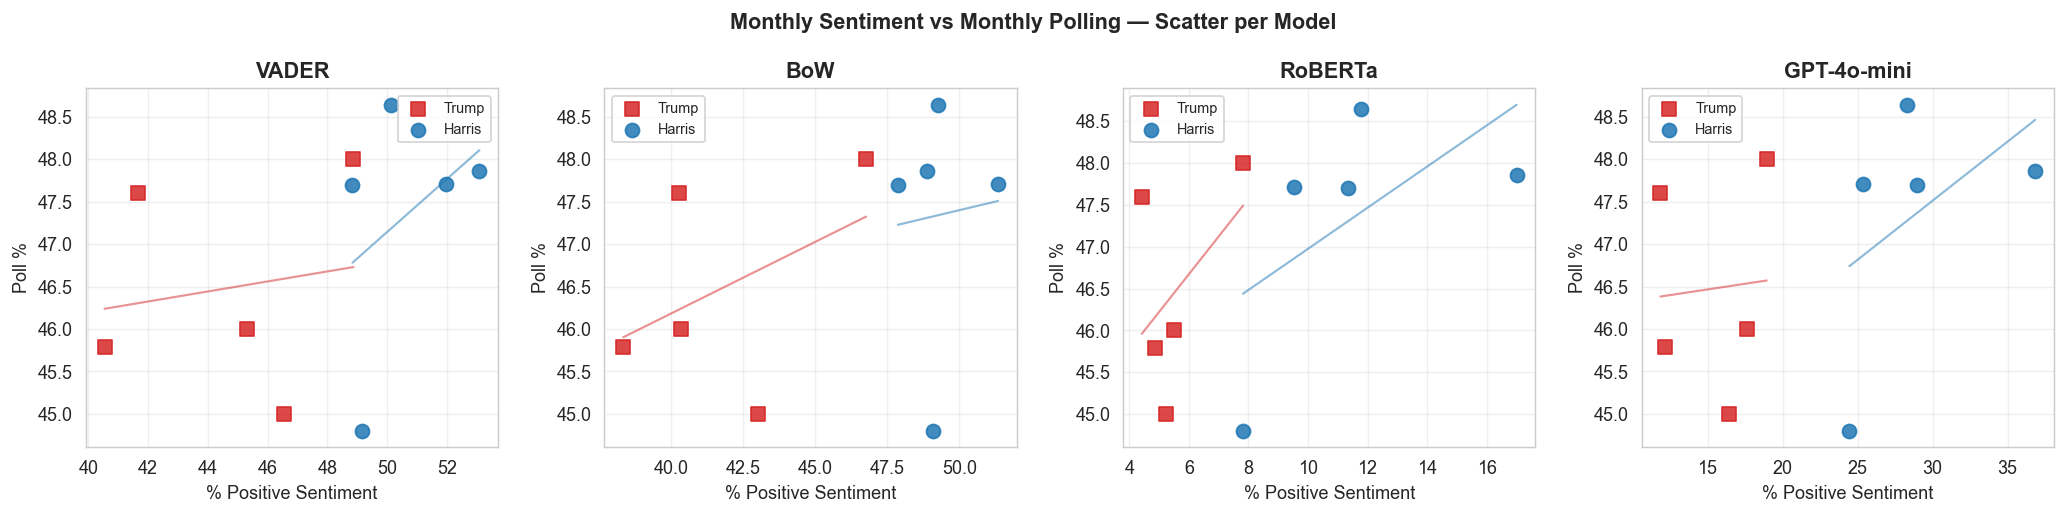

In [20]:
print('Correlation — Monthly Sentiment vs Monthly Polling\n')
print(f'  {"Model":<14} {"Candidate":<10} {"Metric":<12} {"Pearson r":>10} {"p-value":>10} {"Sig":>4}')
print('  ' + '-' * 65)

for col, name in zip(MODELS, MODEL_NAMES):
    if col not in df.columns: continue
    for df_cand, cand, poll_col in [
        (df_trump,  'Trump',  'trump_pct'),
        (df_harris, 'Harris', 'harris_pct'),
    ]:
        for metric_fn, metric_name in [
            (monthly_pos, '% positive'),
            (monthly_net, 'net sent.'),
        ]:
            sent  = metric_fn(df_cand, col).values
            polls = poll_monthly.reindex(MONTHS_ORDER)[poll_col].values
            mask  = ~np.isnan(sent) & ~np.isnan(polls)
            if mask.sum() < 3: continue
            r, p  = stats.pearsonr(sent[mask], polls[mask])
            sig   = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
            print(f'  {name:<14} {cand:<10} {metric_name:<12} {r:>10.4f} {p:>10.4f} {sig:>4}')
    print()

# Visualise: scatter monthly sentiment vs polling for each model
fig, axes = plt.subplots(1, len(MODELS), figsize=(16, 4), sharey=False)
for ax, col, name, color in zip(axes, MODELS, MODEL_NAMES, MODEL_COLORS):
    if col not in df.columns:
        ax.set_visible(False); continue
    for df_cand, cand, poll_col, marker in [
        (df_trump,  'Trump',  'trump_pct',  's'),
        (df_harris, 'Harris', 'harris_pct', 'o'),
    ]:
        sent  = monthly_pos(df_cand, col).values
        polls = poll_monthly.reindex(MONTHS_ORDER)[poll_col].values
        ax.scatter(sent, polls, marker=marker, s=60,
                   color='#d62728' if cand=='Trump' else '#1f77b4',
                   label=cand, alpha=0.85)
        mask = ~np.isnan(sent) & ~np.isnan(polls)
        if mask.sum() >= 3:
            m, b = np.polyfit(sent[mask], polls[mask], 1)
            xs = np.linspace(sent[mask].min(), sent[mask].max(), 50)
            ax.plot(xs, m*xs+b, lw=1.2, alpha=0.5,
                    color='#d62728' if cand=='Trump' else '#1f77b4')
    ax.set_xlabel('% Positive Sentiment'); ax.set_ylabel('Poll %')
    ax.set_title(name, fontweight='bold')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

fig.suptitle('Monthly Sentiment vs Monthly Polling — Scatter per Model', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()